# Project Phase 2 — Statistical Damage Detection

**Course:** CIV E 789 Sensing Techniques and Data Analytics (Fall 2026)  
**Instructor:** Mohammad Talebi-Kalaleh, Ph.D.  
**Group:** 6 (sensors S2, S4, S6, S9, S12, S15, S18, S21, S24)  
**Data:** `phase2_modal_parameters.json` (intact, damage1, damage2; 20 estimates each)

## Contents

0. [Setup](#setup)
1. [Part A: Feature Distribution Analysis](#part-a)
2. [Part B: Single Feature Damage Detection](#part-b)
3. [Part C: Bivariate Analysis](#part-c)
4. [Part D: Feature Fusion and Engineering](#part-d)
5. [Part E: Principal Component Analysis](#part-e)
6. [Part F: Engineering Insights](#part-f)
7. [Use of Generative AI](#ai-note)

<a id="setup"></a>
## 0. Setup

This section loads the data used throughout the project and sets up the common tools. Parts A–E start from the arrays created here, so that all of them work with exactly the same data.

- **0.1** Libraries, paths and helper functions to present tables and figures.
- **0.2** Loading the JSON file and the group 6 sensors.
- **0.3** Extraction of natural frequencies and mode shapes, with automatic checks.

In [1]:
# Google Colab only: mount Google Drive and run from the project folder (does nothing elsewhere)
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

    # Find the project folder wherever it is in the Drive: usual locations first, then a full search
    DRIVE_ROOT = Path('/content/drive')
    PROJECT = 'ProjectPhase2_Group6'
    usual = [f'MyDrive/CIV E 789/{PROJECT}', f'MyDrive/{PROJECT}', f'Shareddrives/*/CIV E 789/{PROJECT}',
             f'.shortcut-targets-by-id/*/CIV E 789/{PROJECT}']
    found = [p for pattern in usual for p in DRIVE_ROOT.glob(pattern)
             if (p / 'phase2_modal_parameters.json').exists()]
    if not found:
        found = [p.parent for p in DRIVE_ROOT.glob(f'**/{PROJECT}/phase2_modal_parameters.json')]
    assert found, f'{PROJECT} folder with phase2_modal_parameters.json not found in Google Drive'
    os.chdir(found[0])
    print('Working folder:', found[0])

### 0.1 Libraries, paths and presentation helpers

- The file `phase2_modal_parameters.json` is searched for first in the notebook folder and, if it is not there, in the parent folder.
- Figures are saved in `figures/part-a/` … `figures/part-e/` and result tables in `results/` (CSV). The folders are created if they do not exist.
- `show_table` places the table caption above the table (**Table N.**) and `show_figure` places the figure caption below the figure (**Figure N.**), both outside the object. `show_figure` also saves the figure in the folder of its part.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Input data: next to this notebook or, if not there, in the parent folder
DATA_FILE = 'phase2_modal_parameters.json'
DATA_PATH = next((p for p in (Path(DATA_FILE), Path('..') / DATA_FILE) if p.exists()), None)
assert DATA_PATH is not None, f'{DATA_FILE} not found next to the notebook or in its parent folder'

# Output folders: one figure folder per part, one folder for result tables
FIG_DIR = Path('figures')
RES_DIR = Path('results')
for part in ['part-a', 'part-b', 'part-c', 'part-d', 'part-e']:
    (FIG_DIR / part).mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


def show_table(df, number, caption, filename=None, precision=4):
    """Show the table caption above the table; optionally save the table as CSV in results/."""
    display(Markdown(f'**Table {number}.** {caption}'))
    display(df.style.format(precision=precision))
    if filename is not None:
        df.to_csv(RES_DIR / filename)


def show_figure(fig, number, caption, part, filename):
    """Save the figure in figures/<part>/, show it and put the caption below it."""
    fig.savefig(FIG_DIR / part / filename, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    display(Markdown(f'**Figure {number}.** {caption}'))

### 0.2 Data loading and group 6 sensors

- The JSON file has two blocks: `scenarios` (data for `intact`, `damage1` and `damage2`) and `metadata` (sampling information, sensors assigned to each group and position of each sensor).
- The group sensors are read from `metadata.sensor_assignments.group_6` instead of being typed by hand, to avoid copying errors.
- Each mode shape is a list of 24 values ordered from S1 to S24, so sensor $S_k$ is at index $k-1$ of the list (Table 1).
- The position of each sensor (`metadata.sensor_positions_m`) will be used as the x-axis of the mode shapes.

In [3]:
with open(DATA_PATH, 'r') as f:
    data = json.load(f)

GROUP = 6
SCENARIOS = ['intact', 'damage1', 'damage2']
MODES = ['mode_1', 'mode_2', 'mode_3']
N_MEAS = data['metadata']['sampling_info']['total_estimates']   # 20 estimates per condition
N_SENSORS_TOTAL = len(data['metadata']['sensor_positions_m'])   # 24 sensors on the bridge

# Sensors assigned to our group, read from the file (not typed by hand)
my_sensors = data['metadata']['sensor_assignments'][f'group_{GROUP}']
SENSOR_IDX = np.array([int(s[1:]) - 1 for s in my_sensors])   # Sk -> list index k - 1
SENSOR_POS = np.array([data['metadata']['sensor_positions_m'][s] for s in my_sensors])   # [m]

sensors_table = pd.DataFrame({'List index': SENSOR_IDX, 'Position (m)': SENSOR_POS},
                             index=pd.Index(my_sensors, name='Sensor'))
show_table(sensors_table, 1, f'Sensors assigned to group {GROUP}, their index in the 24-value lists '
           'and their position along the bridge.', precision=1)

**Table 1.** Sensors assigned to group 6, their index in the 24-value lists and their position along the bridge.

,List index,Position (m)
Sensor,,
S2,1,7.5
S4,3,17.5
S6,5,27.5
S9,8,42.5
S12,11,57.5
S15,14,72.5
S18,17,87.5
S21,20,102.5
S24,23,117.5


### 0.3 Extraction of natural frequencies and mode shapes

The first cell defines the two extraction functions from the assignment starter code (Section 7), with the same names and behaviour: `extract_frequencies(scenario, mode_key)` returns the 20 frequencies of one mode, and `extract_mode_shape(scenario, measurement_idx, mode_key)` returns one mode shape at the 9 group sensors. The second cell uses them to store the data in numpy arrays, one per scenario (Table 2).

**Table 2.** Numpy arrays created in the data extraction.

| Array | Size | Content |
|---|---|---|
| `freqs[scenario]` | 20 × 3 | measurements × modes, natural frequency in Hz |
| `shapes[scenario]` | 3 × 20 × 9 | modes × measurements × group 6 sensors |

- **Assumption:** value $i$ of each frequency list and `measurement_i` of the mode shapes come from the same 30-s segment. The assignment does not state this explicitly. It does not matter for Parts A and B, which analyse each feature separately, but Parts C, D and E combine several features of the same measurement into a single point.
- Measurements are read as `measurement_1` … `measurement_20` in numeric order, not in the order of the JSON keys.
- Mode shapes are not normalized again: they are already scaled to a maximum of 1 over the 24 sensors. The MAC does not depend on scale, so this does not affect it.
- The checks (`assert`) stop the notebook if a measurement is missing, if a mode shape does not have 24 values, or if there are missing values (NaN).

In [4]:
# Extraction functions from the starter code (same names and behaviour)

# Extract frequencies for a scenario
def extract_frequencies(scenario, mode_key='mode_1'):
    return np.array(data['scenarios'][scenario]['natural_frequencies'][mode_key])


# Extract mode shape at assigned sensors
def extract_mode_shape(scenario, measurement_idx, mode_key='mode_1'):
    mode_data = data['scenarios'][scenario]['mode_shapes'][mode_key][f'measurement_{measurement_idx}']
    # mode_data is a list of 24 values ordered S1..S24, so S1 -> index 0
    return np.array([mode_data[int(s[1:]) - 1] for s in my_sensors])

In [5]:
# freqs[scenario]:  (N_MEAS, 3) array -> measurements x modes, in Hz
# shapes[scenario]: (3, N_MEAS, 9) array -> modes x measurements x our 9 sensors
# Measurements are read as measurement_1 ... measurement_20 (numeric order), so row i of
# freqs and measurement i of shapes refer to the same 30-s segment.
freqs = {}
shapes = {}
for sc in SCENARIOS:
    freqs[sc] = np.column_stack([extract_frequencies(sc, m) for m in MODES])
    shapes[sc] = np.array([[extract_mode_shape(sc, i, m) for i in range(1, N_MEAS + 1)]
                           for m in MODES])

# Sanity checks on the raw file and on the extracted arrays
for sc in SCENARIOS:
    for m in MODES:
        assert len(data['scenarios'][sc]['natural_frequencies'][m]) == N_MEAS
        mode_shapes = data['scenarios'][sc]['mode_shapes'][m]
        assert set(mode_shapes) == {f'measurement_{i}' for i in range(1, N_MEAS + 1)}
        assert all(len(v) == N_SENSORS_TOTAL for v in mode_shapes.values())
    assert freqs[sc].shape == (N_MEAS, len(MODES))
    assert shapes[sc].shape == (len(MODES), N_MEAS, len(my_sensors))
    assert np.isfinite(freqs[sc]).all() and np.isfinite(shapes[sc]).all()
print('Extraction checks passed: '
      f'{len(SCENARIOS)} scenarios x {len(MODES)} modes x {N_MEAS} measurements x {len(my_sensors)} sensors')

Extraction checks passed: 3 scenarios x 3 modes x 20 measurements x 9 sensors


In [6]:
# One table per scenario: rows = modes, columns = measurements
for t, sc in enumerate(SCENARIOS, start=3):
    freq_table = pd.DataFrame(freqs[sc].T,
                              index=pd.Index([f'f{k + 1} (Hz)' for k in range(len(MODES))], name='Mode'),
                              columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(freq_table, t, f'Natural frequencies of modes 1–3 for each of the 20 measurements, {sc} scenario.',
               precision=3)

**Table 3.** Natural frequencies of modes 1–3 for each of the 20 measurements, intact scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.063,1.274,1.259,0.973,1.154,1.276,1.103,0.993,1.141,1.096,1.093,1.141,1.059,1.019,1.217,1.091,1.095,1.091,1.327,1.402
f2 (Hz),2.847,3.404,3.253,2.537,3.052,3.345,2.811,2.669,3.038,2.886,2.907,2.943,2.877,2.696,3.303,2.875,2.801,2.855,3.450,3.733
f3 (Hz),4.083,4.945,4.795,3.677,4.330,4.912,4.000,3.792,4.395,4.168,4.154,4.244,4.118,3.935,4.703,4.085,4.164,4.126,4.961,5.368


**Table 4.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage1 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.131,1.191,1.262,1.052,0.994,1.232,1.041,1.096,1.232,1.177,1.190,1.063,1.066,0.940,1.104,1.098,1.154,1.082,0.988,0.966
f2 (Hz),2.777,2.962,3.067,2.769,2.429,3.077,2.727,2.860,3.151,3.105,3.056,2.678,2.714,2.431,2.885,2.778,2.852,2.790,2.549,2.569
f3 (Hz),4.284,4.506,4.717,4.059,3.738,4.581,4.144,4.242,4.728,4.454,4.568,3.997,3.998,3.595,4.202,4.026,4.319,4.054,3.708,3.906


**Table 5.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage2 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.212,1.052,1.095,1.054,1.064,1.035,1.152,1.236,0.943,1.238,0.980,0.991,1.307,1.083,1.004,0.981,1.159,1.096,0.917,1.255
f2 (Hz),2.793,2.557,2.841,2.533,2.621,2.488,2.937,2.989,2.382,3.058,2.453,2.525,3.302,2.712,2.544,2.555,2.955,2.681,2.338,3.016
f3 (Hz),4.491,4.064,4.379,3.992,3.980,4.107,4.360,4.687,3.601,4.589,3.684,3.939,4.851,4.118,3.926,3.802,4.416,4.161,3.572,4.662


<a id="part-a"></a>
## Part A: Feature Distribution Analysis (25 pts)

### A1. Natural Frequency Distributions (8 pts)

### A2. Mode Shape Visualization (9 pts)

### A3. Modal Assurance Criterion (MAC) Distributions (8 pts)

<a id="part-b"></a>
## Part B: Single Feature Damage Detection (20 pts)

### B1. Z-Score Anomaly Detection (10 pts)

### B2. Wasserstein Distance Analysis (7 pts)

### B3. Feature Sensitivity Ranking (3 pts)

<a id="part-c"></a>
## Part C: Bivariate Analysis (20 pts)

### C1. Joint Distribution Visualization (7 pts)

Se analizan dos pares de variables: $(f_1, f_2)$ y $(\mathrm{MAC}_1, \mathrm{MAC}_2)$.

Para calcular el Modal Assurance Criterion (MAC) se utilizó la siguiente ecuación:

$$
\mathrm{MAC} = \frac{\left(\boldsymbol{\phi}_{ref}^{T}\,\boldsymbol{\phi}_{test}\right)^{2}}{\left(\boldsymbol{\phi}_{ref}^{T}\boldsymbol{\phi}_{ref}\right)\left(\boldsymbol{\phi}_{test}^{T}\boldsymbol{\phi}_{test}\right)}
\tag{1}
$$

donde:

- $\boldsymbol{\phi}_{ref}$: forma modal de referencia, igual al promedio de las 20 mediciones del escenario intacto (9 valores, uno por sensor).
- $\boldsymbol{\phi}_{test}$: forma modal de una medición (9 valores).
- $\boldsymbol{\phi}^{T}\boldsymbol{\phi}$: producto punto, es decir, se multiplica sensor por sensor y se suman los resultados.

In [7]:
# MAC (Eq. 1) of each measured mode shape against the intact reference, for modes 1 and 2
def calculate_MAC(phi_ref, phi_test):
    numerator = np.abs(np.dot(phi_ref, phi_test))**2
    denominator = np.dot(phi_ref, phi_ref) * np.dot(phi_test, phi_test)
    return numerator / denominator


MAC_MODES = [0, 1]                               # mode 1 and mode 2 (indices in MODES)
ref_shapes = shapes['intact'].mean(axis=1)       # (3, 9): mean of the 20 intact shapes of each mode

# mac[scenario]: (N_MEAS, 2) array -> measurements x [MAC1, MAC2]
mac = {sc: np.array([[calculate_MAC(ref_shapes[j], shapes[sc][j, i]) for j in MAC_MODES]
                     for i in range(N_MEAS)])
       for sc in SCENARIOS}

# One table per scenario: rows = MAC of each mode, columns = measurements
for t, sc in enumerate(SCENARIOS, start=6):
    mac_table = pd.DataFrame(mac[sc].T,
                             index=pd.Index([f'MAC{j + 1}' for j in MAC_MODES], name='Mode'),
                             columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(mac_table, t, f'MAC of modes 1 and 2 for each of the 20 measurements, {sc} scenario '
               '(reference: mean intact mode shape).', precision=4)

**Table 6.** MAC of modes 1 and 2 for each of the 20 measurements, intact scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,1.0000,0.9999,0.9999,0.9999,0.9999,1.0000,0.9998,0.9996,0.9999,0.9999,0.9993,0.9999,0.9998,1.0000,0.9996,0.9999,0.9992,1.0000,0.9999,0.9999
MAC2,0.9994,0.9991,0.9994,0.9997,0.9952,0.9924,0.9980,0.9987,0.9991,0.9973,0.9991,0.9995,0.9997,0.9977,0.9987,0.9996,0.9985,0.9991,0.9980,0.9994


**Table 7.** MAC of modes 1 and 2 for each of the 20 measurements, damage1 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9996,0.9994,0.9990,0.9995,0.9992,0.9999,0.9993,0.9990,0.9990,1.0000,0.9993,0.9992,0.9998,0.9998,0.9994,0.9999,0.9992,0.9999,0.9996,0.9997
MAC2,0.9905,0.9932,0.9854,0.9982,0.9883,0.9908,0.9936,0.9969,0.9968,0.9981,0.9963,0.9972,0.9969,0.9901,0.9956,0.9984,0.9925,0.9880,0.9954,0.9906


**Table 8.** MAC of modes 1 and 2 for each of the 20 measurements, damage2 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9971,0.9983,0.9987,0.9966,0.9992,0.9971,0.9981,0.9991,0.9989,0.9993,0.9985,0.9996,0.9993,0.9989,0.9993,0.9997,0.9995,0.9981,0.9982,0.9992
MAC2,0.9719,0.9748,0.9890,0.9738,0.9895,0.9674,0.9918,0.9776,0.9936,0.9866,0.9928,0.9852,0.9908,0.9899,0.9921,0.9863,0.9963,0.9758,0.9854,0.9789


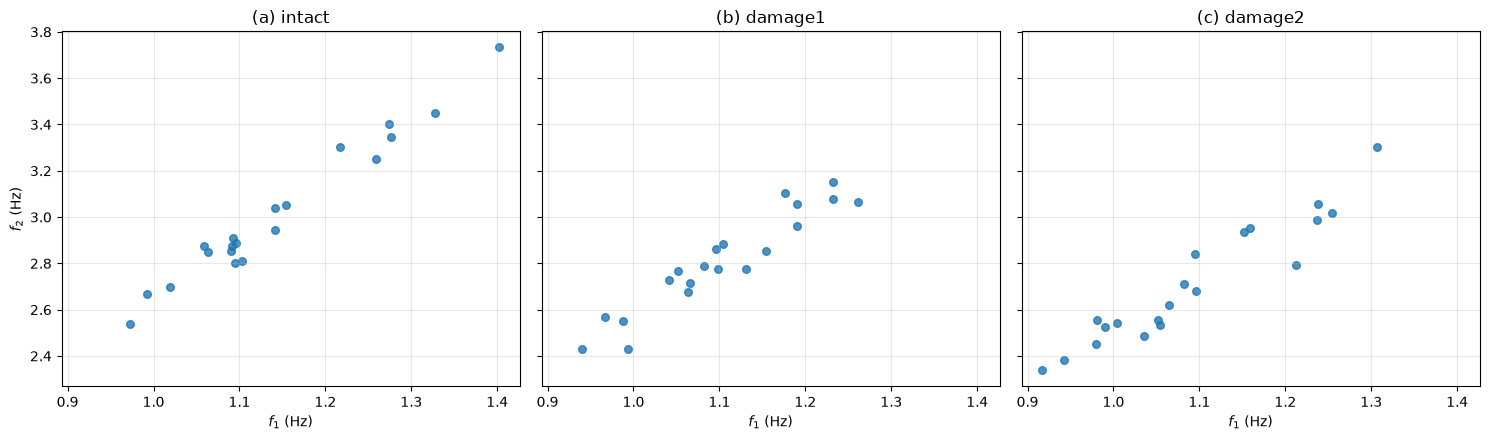

**Figure 1.** Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each scenario: (a) intact, (b) damage1, (c) damage2.

In [8]:
# Scatter of (f1, f2) for each scenario; same axis limits in all panels to compare them
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
    ax.scatter(freqs[sc][:, 0], freqs[sc][:, 1], s=30, alpha=0.8)
    ax.set_title(f'{label} {sc}')
    ax.set_xlabel('$f_1$ (Hz)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('$f_2$ (Hz)')
fig.tight_layout()
show_figure(fig, 1, 'Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each '
            'scenario: (a) intact, (b) damage1, (c) damage2.', 'part-c', 'C1_f1_f2_scatter.png')

### C2. Mahalanobis Distance Detection (8 pts)

### C3. Bivariate vs Univariate Comparison (5 pts)

<a id="part-d"></a>
## Part D: Feature Fusion and Engineering (15 pts)

### D1. Systematic Combination Testing (10 pts)

### D2. Feature Importance Analysis (5 pts)

<a id="part-e"></a>
## Part E: Principal Component Analysis (15 pts)

### E1. PCA Implementation and Variance Analysis (4 pts)

### E2. First Principal Component Analysis (3 pts)

### E3. Two-Dimensional PCA Space (3 pts)

### E4. Progressive Dimensionality Impact (3 pts)

### E5. Physical Interpretation (2 pts)

<a id="part-f"></a>
## Part F: Engineering Insights (5 pts)

### F1. Method Comparison and Selection (2 pts)

### F2. Feature Selection Strategy (2 pts)

### F3. Practical Implementation Considerations (1 pt)

<a id="ai-note"></a>
## Use of Generative AI